# k-Means

[Vortragsaufzeichnung zu k-Means](https://media.hhu.de/channel/video/data-science-vl-16-k-means-2025/4d7a11c94e56a89a8bd8acdeb03a7a0d/167)


k-Means ist ein unsupervised learning Verfahren um einen Datensatz in $k$ Cluster einzuteilen. Je nach Datenform kann k-Means bereits ausreichen für eine Klassifikation / einen Prädiktor, oder aber als Ausgangsbasis für komplexere Algorithmen dienen. Das $k$ ist die Anzahl der Cluster, die vorher festgelegt werden muss. Es gibt Heuristiken, das 'optimale' $k$ zu bestimmen. Eine dieser Heuristiken ist, mit $k=2$ anfangend Plots der Cluster zu betrachten, bis man zufrieden ist.

Zunächst gehen wir in Pseudocode die Idee durch, am Beispiel der ersten zwei Spalten Iris-Daten in $\mathbb{R}^n$ mit $n=2$:
1. Wir legen ein $k$ fest, die Anzahl an Clustern. Im Beispiel Iris: 3
2. Wir legen $k$ verschiedene Punkte $c_1,\dots,c_k \in \mathbb{R}^n$ fest, die 'Zentroide'. Es ist möglich, sich auf Punkte aus dem Datensatz zu beschränken und diese Wahl einfach gleichverteilt zufällig zu treffen.
3. Zu jedem weiteren Punkt $x \in \mathbb{R}^n$ berechnen wir, welches Zentroid $c_i$ den geringsten Abstand hat und ordnen $x$ der Gruppe $i$ zu.
4. Dann updaten wir das $i$-te Zentroid als Mittelwert aller Punkte aus der Gruppe $i$. Wenn sich dabei nichts (bzw. wenig genug) ändert, sind wir fertig.

## Eine k-Means Iteration

In [1]:
import numpy as np
np.random.seed(2222)
import matplotlib.pyplot as plt
from sklearn import datasets

iris = datasets.load_iris()
# permute the data to make it look less sorted by class already:
permutation = np.random.permutation(np.arange(len(iris.data)))
x = iris.data[permutation]
classes = iris.target[permutation]

In [2]:
k = 3
demodata = x[:, 2:4] # petal length, petal width
random_indices = np.random.choice(len(demodata), k)
initial_cs = demodata[random_indices]
cs = np.copy(initial_cs)
print(cs)

[[4.5 1.5]
 [1.3 0.2]
 [6.1 1.9]]


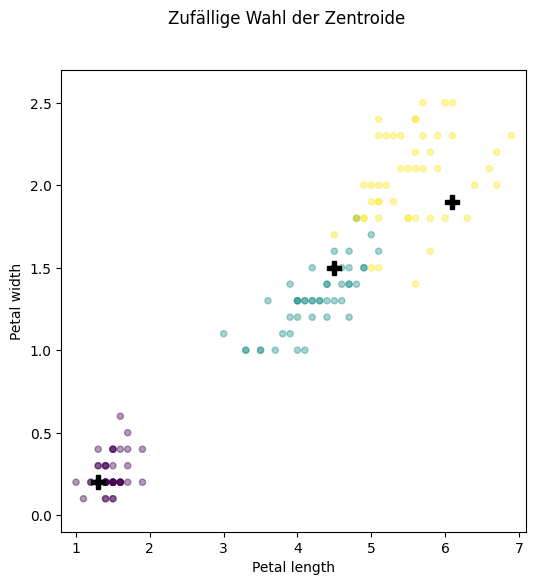

In [3]:
def plotinit(the_data):
    fig, ax = plt.subplots(figsize=(6,6))
    ax.set_xlim(np.min(the_data[:,0])-0.2, np.max(the_data[:,0])+0.2)
    ax.set_ylim(np.min(the_data[:,1])-0.2, np.max(the_data[:,1])+0.2)
    ax.set_xlabel("Petal length")
    ax.set_ylabel("Petal width")
    return fig, ax

fig, ax = plotinit(demodata)
ax.scatter(demodata[:,0], demodata[:,1],
           c=classes, vmax=k-1,
           alpha=0.4, s=20)
ax.plot(cs[:,0], cs[:,1],
        'P', c='black', markersize=10)
fig.suptitle("Zufällige Wahl der Zentroide")
plt.show()

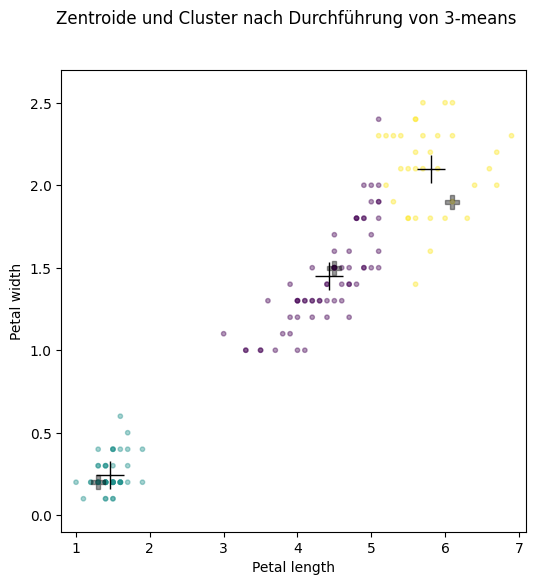

In [4]:
# Wir legen die von k-means geratene Klasse in eine neue Spalte ab:
point_classification = np.full(len(demodata), -1.0)

# Wir merken uns die Geschichte der Zentroide zum Plotten:
cs_history = np.full((len(demodata),k,len(demodata[0])), -1.0)

# Punkt für Punkt wird klassifiziert:
for i, point in enumerate(demodata):
    # Nächstes Zentroid bestimmen:
    distances = [np.linalg.norm(centroid - point) 
                 for centroid in cs]
    pointclass = np.argmin(distances)
    point_classification[i] = pointclass
    # Im ersten Durchlauf werden wir sofort,
    # nicht erst nach dem Durchlauf, das
    # Zentroid neu berechnen:
    cs_history[i] = cs
    cs[pointclass,:] = np.mean(demodata[point_classification == pointclass],
                              axis=0)

# Ergebnisse betrachten:
fig, ax = plotinit(demodata)
ax.scatter(demodata[:,0], demodata[:,1],
           c=point_classification, vmax=k-1,
           alpha=0.4, s=10)
ax.plot(initial_cs[:,0], initial_cs[:,1],
        'P', c='black', markersize=10, alpha=0.4)
ax.plot(cs[:,0], cs[:,1],
        '+', c='black', markersize=20)
fig.suptitle("Zentroide und Cluster nach Durchführung von 3-means")
plt.show()

In [5]:
# Klassenbezeichnungen sind permutiert,
# Zur besseren Visualisierung 'reparieren' wir das,
# dann passen die Farben mit den ursprünglichen Klassen zusammen:
point_classification[point_classification == 0] = 3
point_classification[point_classification == 1] = 0
point_classification[point_classification == 3] = 1

Wie der Algorithmus iterativ die Punkte clustert, kann man sich auch in Ruhe anschauen:

In [6]:
import matplotlib.animation as animation
from IPython import display as ipydisplay

fig, ax = plotinit(demodata)
fig.set_size_inches(9, 9)

def init():
    ax.scatter(demodata[:,0], demodata[:,1],
           c=classes, vmax=k-1, alpha=0.2, s=200)
    
def update(i):
    ax.clear()
    init()
    ax.scatter(demodata[:i+1,0], demodata[:i+1,1],
               vmax=k-1,
               c=point_classification[:i+1],
               marker='s', s=50)
    ax.plot(cs_history[i,:,0], cs_history[i,:,1],
        '+', c='black', markersize=30)

ani = animation.FuncAnimation(fig, update,
                              frames=len(demodata), interval=100,
                              init_func=init)
video = ani.to_html5_video()
html = ipydisplay.HTML(video)
ipydisplay.display(html)
plt.close()

<!-- [kmeans-in-action.mp4](kmeans-in-action.mp4) -->


Man sieht hier, dass wir das Verfahren erneut durchführen können, mit den neuen Zentroiden als Startzentroide, und dabei ein besseres Clustering bekommen. Wenn sich bei wiederholter Durchführung die Cluster (also auch die Zentroide) nicht mehr ändern, spricht man von *Konvergenz*.
Bessere Cluster bekommt man natürlich, wenn man den vollen Datensatz verwendet (also nicht nur 2 Spalten). Wir wollen nun eine Methode implementieren, die einen k-Means-Durchlauf auf einem beliebigen Datensatz durchführt mit vorgegebenen Initialzentroiden. Dabei können wir gleich die vorherige Implementierung durch eine vektorisierte ersetzen:

## Vektorisierte k-Means-Implementierung

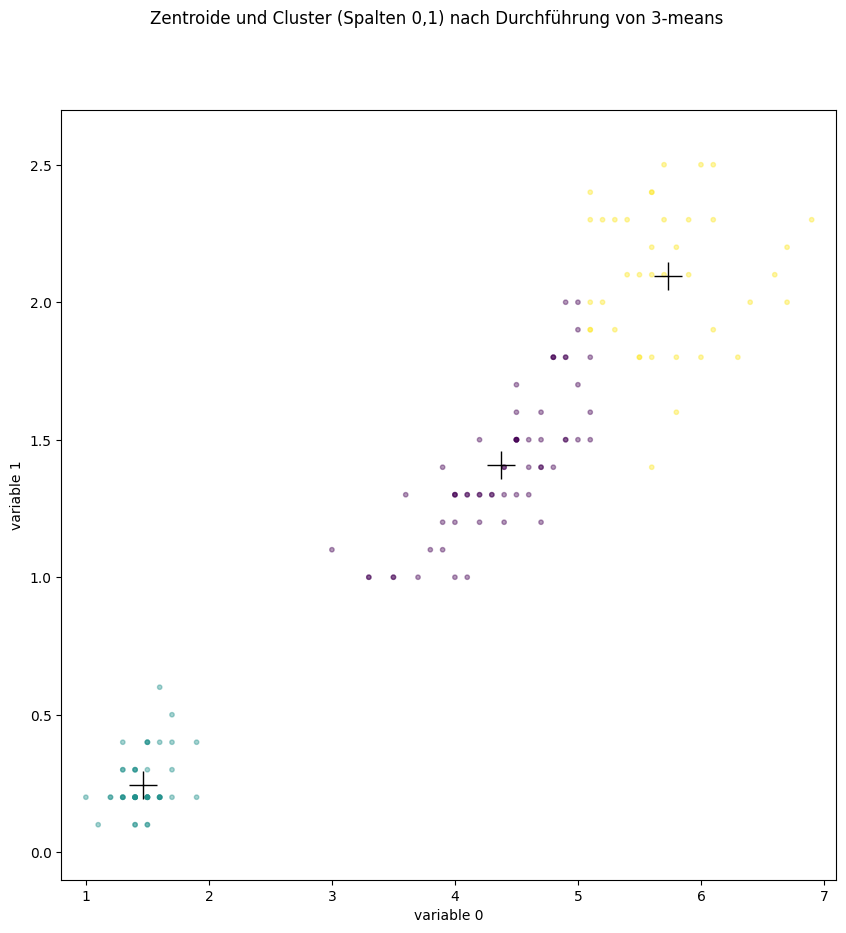

In [7]:
def kmeans(data, k, centroids):
    alldistances = np.array([np.linalg.norm(data - centroid, axis=1)
                             for centroid in centroids])
    assert alldistances.shape == (k, len(data))
    point_classification = np.argmin(alldistances, axis=0)
    new_centroids = np.array([np.mean(data[point_classification == pointclass],
                                      axis=0)
                              for pointclass in np.arange(k)])
    return point_classification, new_centroids

point_classification, new_centroids = kmeans(demodata, 3, cs_history[-1])

# Ergebnisse betrachten:
def plotinit(data, col1=0, col2=1):
    fig, ax = plt.subplots(figsize=(10,10))
    ax.set_xlim(np.min(data[:,col1])-0.2, np.max(data[:,col1])+0.2)
    ax.set_ylim(np.min(data[:,col2])-0.2, np.max(data[:,col2])+0.2)
    ax.set_xlabel("variable %s" % col1)
    ax.set_ylabel("variable %s" % col2)
    return fig, ax

def plot_results(data, k, centroids, classes, col1=0, col2=1):
    fig, ax = plotinit(data, col1=col1, col2=col2)
    ax.scatter(data[:,col1], data[:,col2],
               c=classes, vmax=k-1,
               alpha=0.4, s=10)
    ax.plot(centroids[:,col1], centroids[:,col2],
            '+', c='black', markersize=20)
    fig.suptitle("Zentroide und Cluster (Spalten %s,%s) nach Durchführung von %s-means" % (col1, col2, k))
    plt.show()
    
plot_results(demodata, 3, new_centroids, point_classification, col1=0, col2=1)

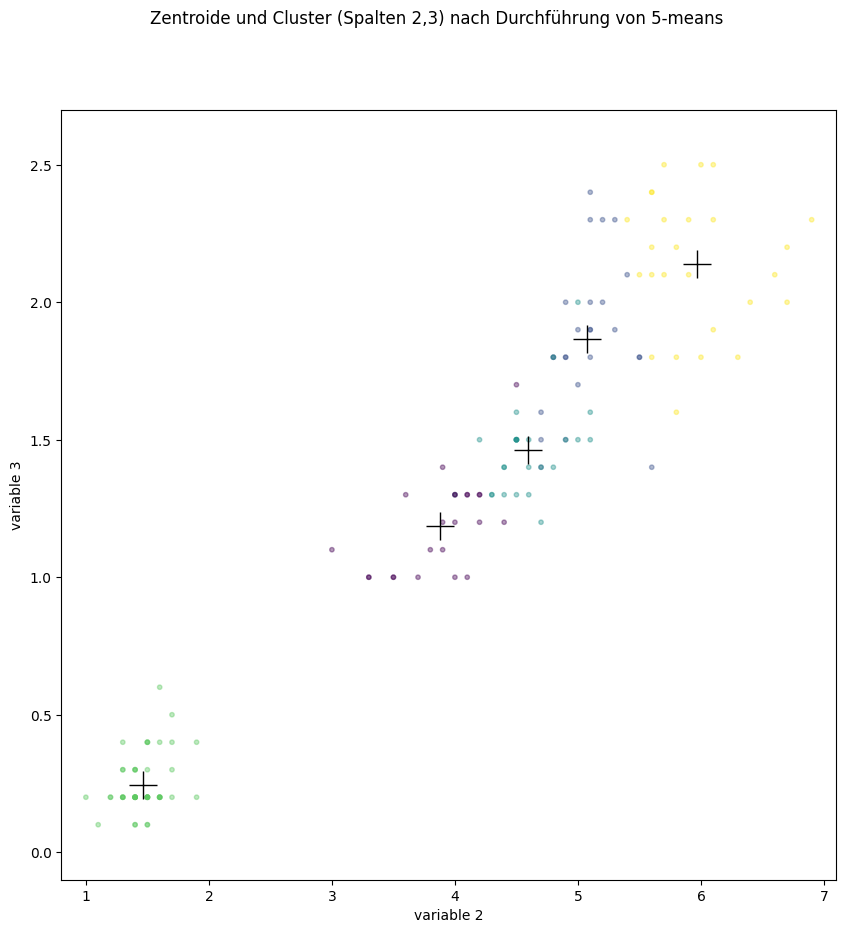

In [8]:
# Weil es jetzt so einfach geht:
k = 5
data = x # sepal length, sepal width, petal length, petal width
random_indices = np.random.choice(len(data), k)
initial_centroids = data[random_indices]
point_classification, new_centroids = kmeans(data, k, initial_centroids)
plot_results(data, k, new_centroids, point_classification, col1=2, col2=3)

## Konvergierende k-Means-Implementierung

iteration step  1
iteration step  2
iteration step  3
iteration step  4
iteration step  5
iteration step  6


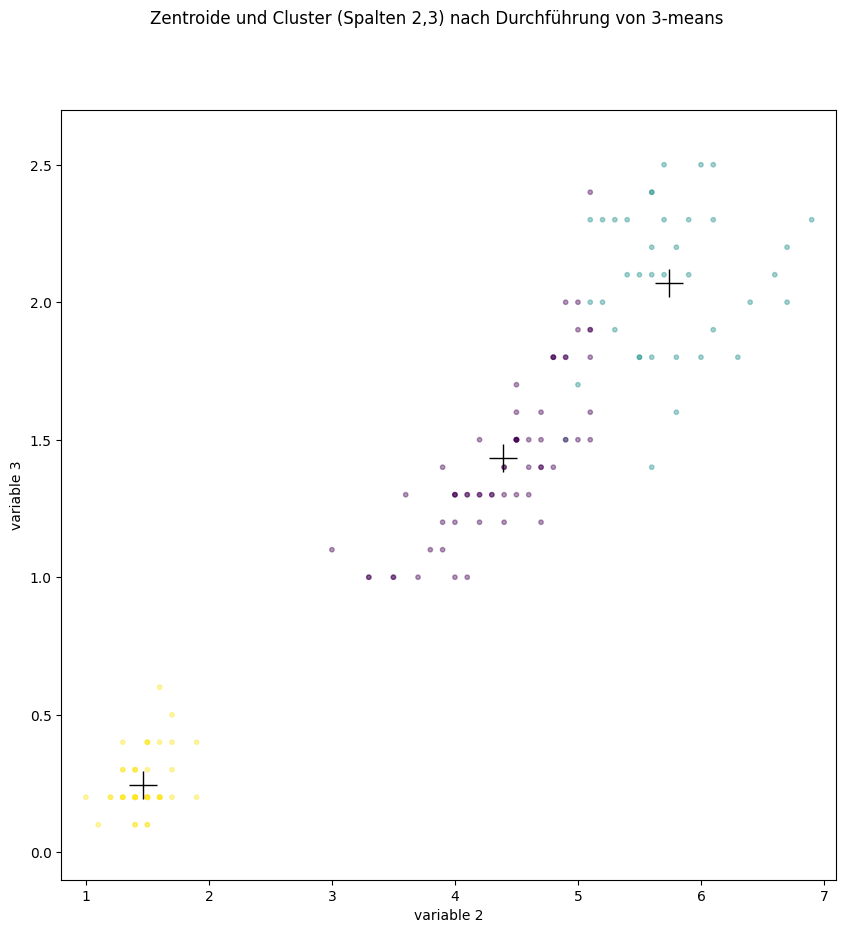

In [9]:
np.random.seed(2222)

# 3-means bis zur Konvergenz:
def convergent_kmeans(data, k, breakloop=100, noisy=True):
    random_indices = np.random.choice(len(data), k)
    new_centroids = data[random_indices]
    old_centroids = np.full(new_centroids.shape, 0) # will be overwritten anyway
    point_classification = None
    i = 0
    while(not np.allclose(old_centroids, new_centroids, rtol=0.0001) and i < breakloop):
        i += 1
        if(noisy):
            print("iteration step ", i)
        old_centroids = new_centroids
        point_classification, new_centroids = kmeans(data, k, old_centroids)
        # if any of the new centroids is NaN, need to replace it by the old one to continue
        # this can happen if centroid is so bad, the empty cluster forms (=> no mean)
        nan_centroids = np.isnan(new_centroids).any(axis=1)
        new_centroids[nan_centroids] = old_centroids[nan_centroids]
    return point_classification, new_centroids

point_classification, new_centroids = convergent_kmeans(data, 3)
plot_results(data, 3, new_centroids, point_classification, col1=2, col2=3)

## Welches k ist das richtige?

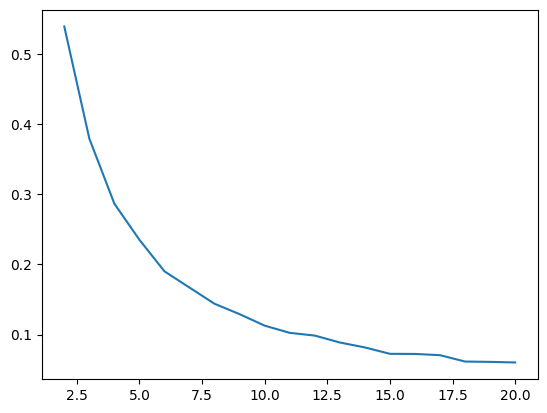

In [10]:
np.random.seed(11111)
max_k_to_try = 20
assert max_k_to_try <= len(data)

import warnings
warnings.simplefilter("ignore") # Mean of empty slice

elbow_values = []
for k in range(2, max_k_to_try+1):
    #print("looking at k =", k)
    point_classification, centroids = convergent_kmeans(data, k, noisy=False)
    # Berechne für jeden Cluster die innere Varianz:
    total_inner_variance = np.nansum([np.var(data[point_classification == pointclass])
                                      for pointclass in range(k)])
    group_variance = np.var(centroids)
    elbow_values.append(group_variance / total_inner_variance)
    
fig, ax = plt.subplots()
ax.plot(np.arange(2, max_k_to_try+1), elbow_values)
plt.show()

## Robustes k-Means und Elbow plot

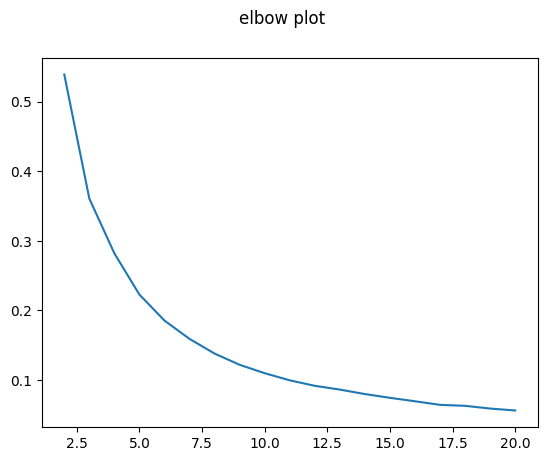

In [11]:
def robust_kmeans(data, k, howmany=20):
    score = 100000000
    for i in range(howmany):
        point_classification, centroids = convergent_kmeans(data, k, noisy=False)
        total_inner_variance = np.nansum([np.var(data[point_classification == pointclass])
                                          for pointclass in range(k)])
        group_variance = np.var(centroids)
        new_score = group_variance / total_inner_variance
        if(new_score < score):
            final_classification, final_centroids = point_classification, centroids
            score = new_score
    return final_classification, final_centroids, score

elbow_values = [robust_kmeans(data, k)[2] for k in range(2, max_k_to_try+1)]
fig, ax = plt.subplots()
fig.suptitle("elbow plot")
ax.plot(np.arange(2, max_k_to_try+1), elbow_values)
plt.show()

## Beispiel mit anderen Daten

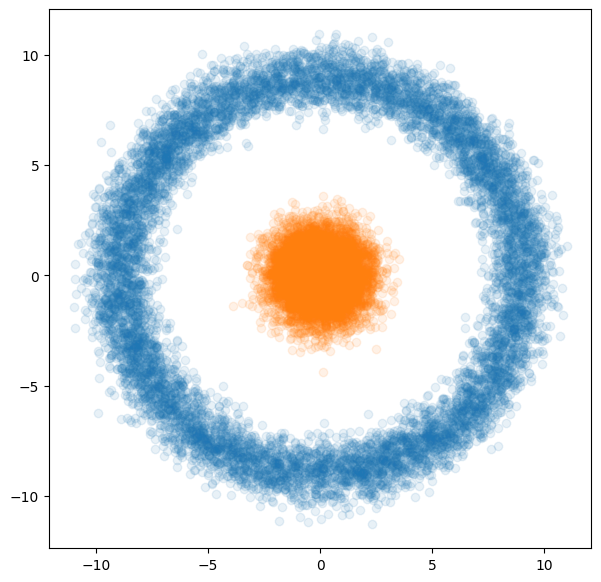

In [12]:
import scipy.stats as st

def X(n, radius=[8,9]):
    rs = st.multivariate_normal(mean=radius[0]+np.ptp(radius),
                                cov=np.ptp(radius)/2
                               ).rvs(size=n)
    phis = st.uniform.rvs(size=n) * 2 * np.pi
    x, y = np.cos(phis), np.sin(phis)
    return (rs * np.stack([x, y])).T

n = 10000
sample = X(n)
secondsample = st.multivariate_normal.rvs(mean=[0,0], cov=np.eye(2), size=n)
fig, ax = plt.subplots(figsize=(7,7))
ax.scatter(sample[:,0], sample[:,1], alpha=1000/n)
ax.scatter(secondsample[:,0], secondsample[:,1], alpha=1000/n)
plt.show()

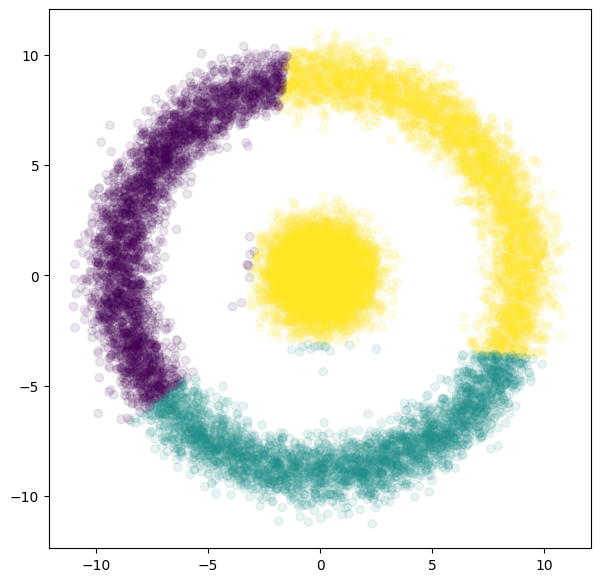

In [13]:
merged_sample = np.concatenate([sample, secondsample])
final_classification, final_centroids, score = robust_kmeans(merged_sample, 3, howmany=10)
#final_classification, final_centroids = convergent_kmeans(merged_sample, 3, breakloop=100, noisy=False)
fig, ax = plt.subplots(figsize=(7,7))
ax.scatter(merged_sample[:,0], merged_sample[:,1], alpha=0.1, c=final_classification)
plt.show()

## kmeans++

Um dem Problem schlechter initialer Zentroide entgegen zu wirken, kann man den **kmeans++**-Algorithmus verwenden:
1. Wähle ein erstes Zentroid gleichverteilt unter allen Datenpunkten
1. Für jeden Punkt $x$, berechne $D(x)$, den Abstand zum nächsten Zentroid
1. Wähle ein nächstes Zentroid aus, mit einer gewichteten Verteilung, die jedes $x$ mit Gewicht proportional zu $D(x)^2$ auswählt.
1. Wiederhole Schritte 2-3 bis $k$ Zentroide gefunden sind.
1. Gewöhnliches k-Means bis zur Konvergenz

In [14]:
def kmeanspp(data, k):
    centroid_indices = [np.random.choice(len(data))] # uniform
    while(len(centroid_indices) < k):
        distances = np.array([np.linalg.norm(data-centroid, axis=1)
                              for centroid in data[centroid_indices]])
        smallest_distances = np.min(distances, axis=0)
        weights = np.power(smallest_distances, 2)
        # must normalize weights to sum up to 1:
        weights = weights / np.sum(weights)
        new_centroid_index = np.random.choice(len(data), p=weights)
        if(not new_centroid_index in centroid_indices):
            centroid_indices += [new_centroid_index]
    return data[centroid_indices]

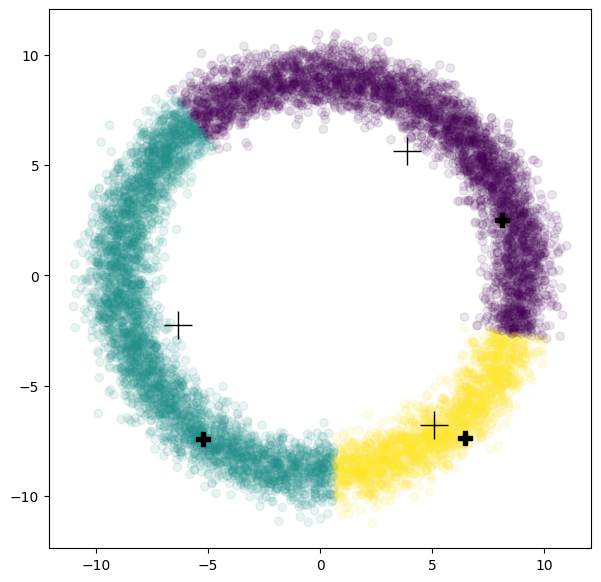

In [15]:
centroids = kmeanspp(sample, 3)
point_classification, new_centroids = kmeans(sample, 3, centroids)
fig, ax = plt.subplots(figsize=(7,7))
ax.scatter(sample[:,0], sample[:,1], alpha=0.1, c=point_classification)
ax.plot(new_centroids[:,0], new_centroids[:,1],
            '+', c='black', markersize=20)
ax.plot(centroids[:,0], centroids[:,1],
        'P', c='black', markersize=10)
plt.show()

## Trivia

Was man über k-Means noch wissen sollte:

* Die durchschnittliche Laufzeitkomplexität ist in $O(k*n*T)$ mit $n$ der Samplegröße und $T$ die Anzahl an Iterationen.
* Die Worst-Case-Komplexität ist in $O(n^{(k+2/p)})$ wobei $p$ die Anzahl Variablen (die Dimension) ist. [Arthur, Vassilvitskii: ‘How slow is the k-means method?’, 2006](https://theory.stanford.edu/~sergei/papers/kMeans-socg.pdf)
* Was passiert theoretisch?
  Die sogenannte **Trägheit**, das ist die Summe der Abstände aller Punkte zu ihren nächsten Zentroiden, wird minimiert. Das zeigt auch das größte Problem auf: wenn die Cluster nicht konvex und homogen sind, ist das eine weniger sinnvolle Optimierungsgröße. Hier greift der Fluch der Dimensionalität (curse of dimensionality): in hochdimensionalen Räumen verhalten sich Abstände unintuitiv, z.B. sind in einer Sphäre gleichverteilte Punkte mehr nahe am Rand als nahe der Mitte. Wieder ein Grund mehr, um Hauptachsentransformation zu lernen.
* Variante **bisecting k-means**:
  Zunächst 2-means, dann wird iterativ einer der größten Cluster aufgeteilt mit 2-means usw. bis insgesamt k Cluster da sind.
* Variante **mini-batch k-means**:
  Ein Kompromiss aus unserer ersten Variante (mit der Animation) und der letzten Variante. Hat große Vorteile bei online-Datenverarbeitung (streaming) und generell großen Datenmengen.
* Die Voraussetzung, damit k-means-Verfahren erfolgreich sein können, sind Daten die in Cluster von etwa Ellipsoider Form mit ähnlicher Varianz fallen. [Beispiele, wo es schief gehen kann, sind in der scikit-learn-Dokumentation geplottet](https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_assumptions.html#sphx-glr-auto-examples-cluster-plot-kmeans-assumptions-py).
* Das **Elbow Kriterium** ist nicht sinnvoll. Details und Alternativen werden seit Jahren in der Literatur diskutiert {cite}`Schubert2023`.

## k-Means in scikit-learn

Man muss natürlich das Rad nicht neu erfinden, `scikit-learn` bringt k-Means-Implementierungen mit:

In [16]:
from sklearn.cluster import KMeans
# Ist natürlich viel schneller, weil mit C parallelisiert:
kmeans_result = KMeans(n_clusters=3).fit(iris.data)
print(kmeans_result.cluster_centers_)
print(kmeans_result.labels_)
print(iris.target)
from sklearn import metrics
print("P = Predicted, C = Class, H(P, C)/mean(H(P),H(C)) =",
      metrics.normalized_mutual_info_score(iris.target, kmeans_result.labels_))

[[6.85384615 3.07692308 5.71538462 2.05384615]
 [5.006      3.428      1.462      0.246     ]
 [5.88360656 2.74098361 4.38852459 1.43442623]]
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 0 0 0 0 2 0 0 0 0
 0 0 2 2 0 0 0 0 2 0 2 0 2 0 0 2 2 0 0 0 0 0 2 0 0 0 0 2 0 0 0 2 0 0 0 2 0
 0 2]
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]
P = Predicted, C = Class, H(P, C)/mean(H(P),H(C)) = 0.7419116631817836


In [17]:
# Das gibt's auch noch:
from sklearn.cluster import MiniBatchKMeans
#from sklearn.cluster import BisectingKMeans # in sklearn v.1.1